# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv("data/AviationData_cleaned.csv")

print(df.shape)
print("Mean fatal/serious fraction:", df["Fatal.Serious.Fraction"].mean())
print("Share of accidents that destroyed the aircraft:", df["Destroyed"].mean())
df.head()

(56482, 32)
Mean fatal/serious fraction: 0.2700275060615925
Share of accidents that destroyed the aircraft: 0.20661449665380122


C:\Users\jeanf\AppData\Local\Temp\ipykernel_34620\3754704180.py:1: DtypeWarning: Columns (6,7,25) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/AviationData_cleaned.csv")


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Make.Model,Total.Passengers,Fatal.Serious.Fraction,Destroyed
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,1.0,3.0,VMC,Approach,Probable Cause,NaN,CESSNA 182P,4.0,0.0,0
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,CESSNA 182RG,2.0,0.0,0
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,CESSNA 182P,1.0,0.0,0
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,2.0,0.0,VMC,Approach,Probable Cause,NaN,PIPER PA28R200,2.0,0.0,0
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,CESSNA 140,2.0,0.0,0


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Passenger threshold that separates small and large airplanes
PASSENGER_THRESHOLD = 20

avg_passengers = df.groupby("Make.Model")["Total.Passengers"].mean()
df["Type.Avg.Passengers"] = df["Make.Model"].map(avg_passengers)

def size_label(avg):
    if avg >= PASSENGER_THRESHOLD:
        return "Large"
    return "Small"

df["Size"] = df["Type.Avg.Passengers"].apply(size_label)

small = df[df["Size"] == "Small"]
large = df[df["Size"] == "Large"]

print("Small plane accidents:", len(small), "| makes:", len(small["Make"].unique()), "| types:", len(small["Make.Model"].unique()))
print("Large plane accidents:", len(large), "| makes:", len(large["Make"].unique()), "| types:", len(large["Make.Model"].unique()))

Small plane accidents: 55388 | makes: 47 | types: 1429
Large plane accidents: 1094 | makes: 8 | types: 190


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

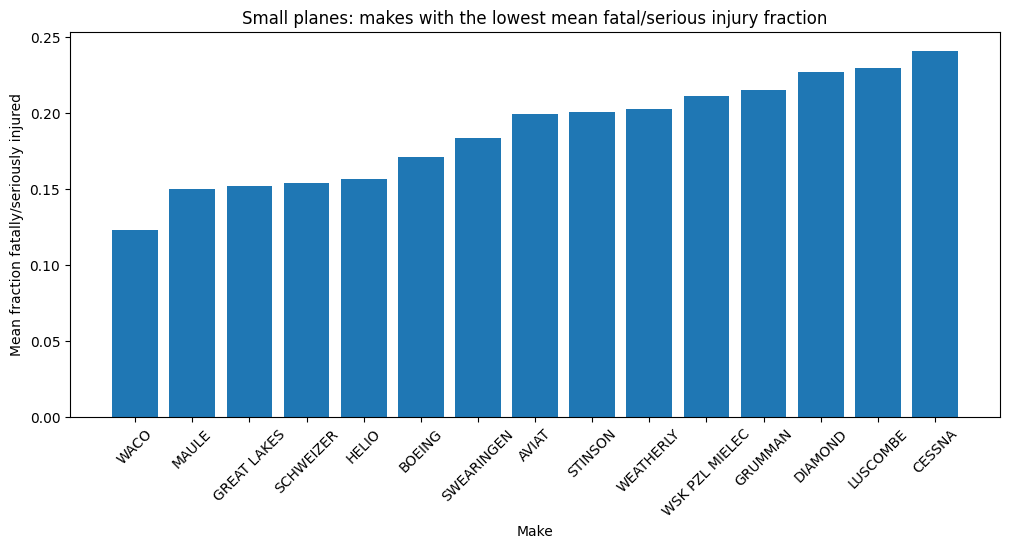

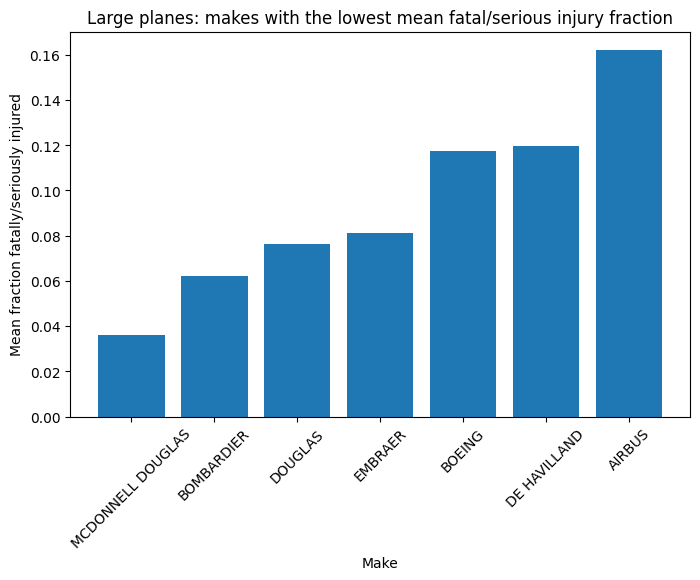

                Fatal.Serious.Fraction  Destroyed      n
Make                                                    
WACO                          0.123397   0.096154    104
MAULE                         0.150313   0.086466    532
GREAT LAKES                   0.151786   0.125000     56
SCHWEIZER                     0.154088   0.185984    371
HELIO                         0.156600   0.150685     73
BOEING                        0.171178   0.121547    362
SWEARINGEN                    0.183801   0.170732    123
AVIAT                         0.199552   0.062780    223
STINSON                       0.200534   0.128079    406
WEATHERLY                     0.202532   0.215190     79
WSK PZL MIELEC                0.210938   0.281250     64
GRUMMAN                       0.215146   0.245484   1218
DIAMOND                       0.226885   0.077381    168
LUSCOMBE                      0.229337   0.100817    367
CESSNA                        0.241081   0.188460  24939
                   Fatal.Seriou

In [4]:
# Mean fatal/serious fraction, mean destruction rate and number of accidents for each group of planes
def summary_table(group, column, min_accidents):
    table = group.groupby(column)[["Fatal.Serious.Fraction", "Destroyed"]].mean()
    table["n"] = group[column].value_counts()
    return table[table["n"] >= min_accidents]

small_makes = summary_table(small, "Make", 30).sort_values("Fatal.Serious.Fraction")
large_makes = summary_table(large, "Make", 10).sort_values("Fatal.Serious.Fraction")

best_small = small_makes.head(15)
best_large = large_makes.head(15)   # only a few large makes have 10+ accidents

plt.figure(figsize=(12, 5))
plt.bar(best_small.index, best_small["Fatal.Serious.Fraction"])
plt.title("Small planes: makes with the lowest mean fatal/serious injury fraction")
plt.xlabel("Make")
plt.ylabel("Mean fraction fatally/seriously injured")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(best_large.index, best_large["Fatal.Serious.Fraction"])
plt.title("Large planes: makes with the lowest mean fatal/serious injury fraction")
plt.xlabel("Make")
plt.ylabel("Mean fraction fatally/seriously injured")
plt.xticks(rotation=45)
plt.show()

print(best_small)
print(best_large)

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

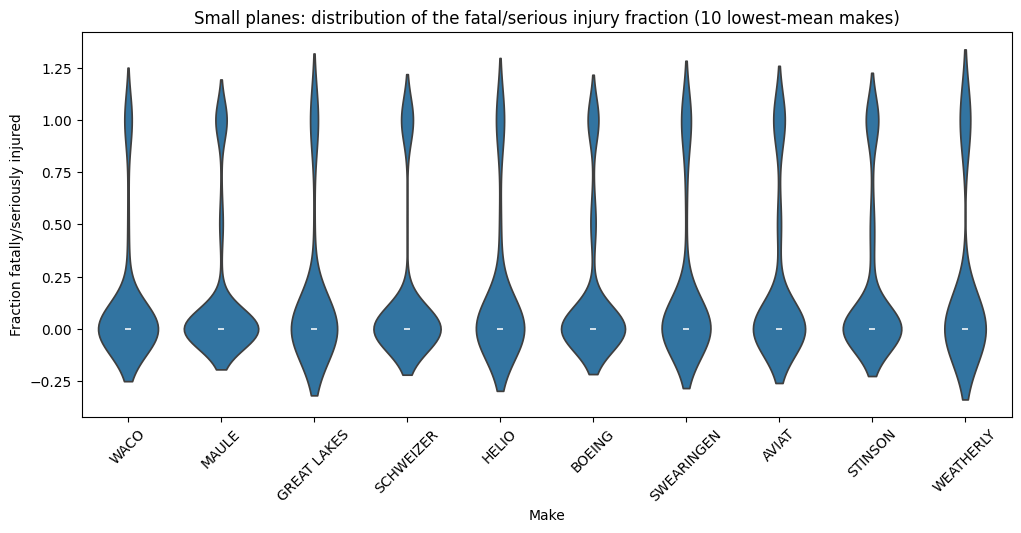

In [5]:
# Event-level data for the 10 small makes with the lowest mean, stacked in ranking order
top10_small = best_small.head(10).index
small_top10_data = pd.concat([small[small["Make"] == make] for make in top10_small])

plt.figure(figsize=(12, 5))
sns.violinplot(data=small_top10_data, x="Make", y="Fatal.Serious.Fraction")
plt.title("Small planes: distribution of the fatal/serious injury fraction (10 lowest-mean makes)")
plt.ylabel("Fraction fatally/seriously injured")
plt.xticks(rotation=45)
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

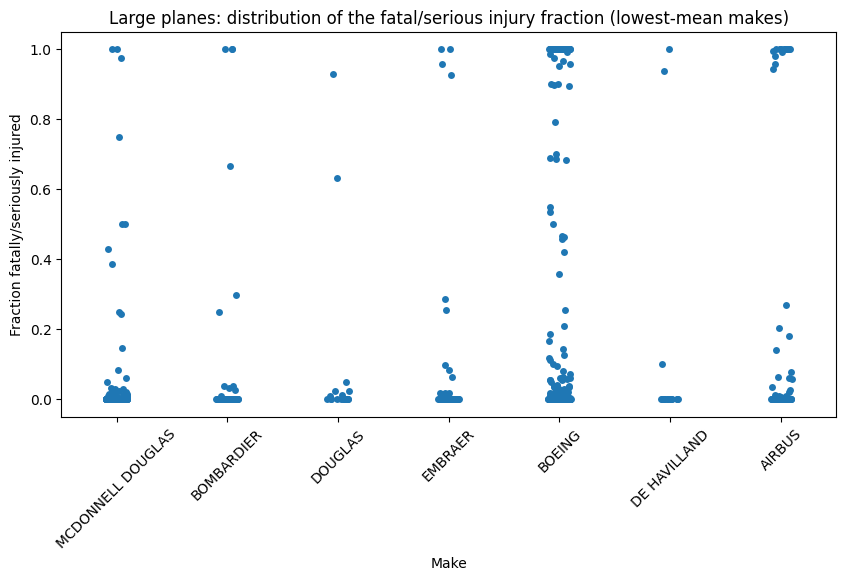

In [6]:
top10_large = best_large.head(10).index
large_top10_data = pd.concat([large[large["Make"] == make] for make in top10_large])

plt.figure(figsize=(10, 5))
sns.stripplot(data=large_top10_data, x="Make", y="Fatal.Serious.Fraction")
plt.title("Large planes: distribution of the fatal/serious injury fraction (lowest-mean makes)")
plt.ylabel("Fraction fatally/seriously injured")
plt.xticks(rotation=45)
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

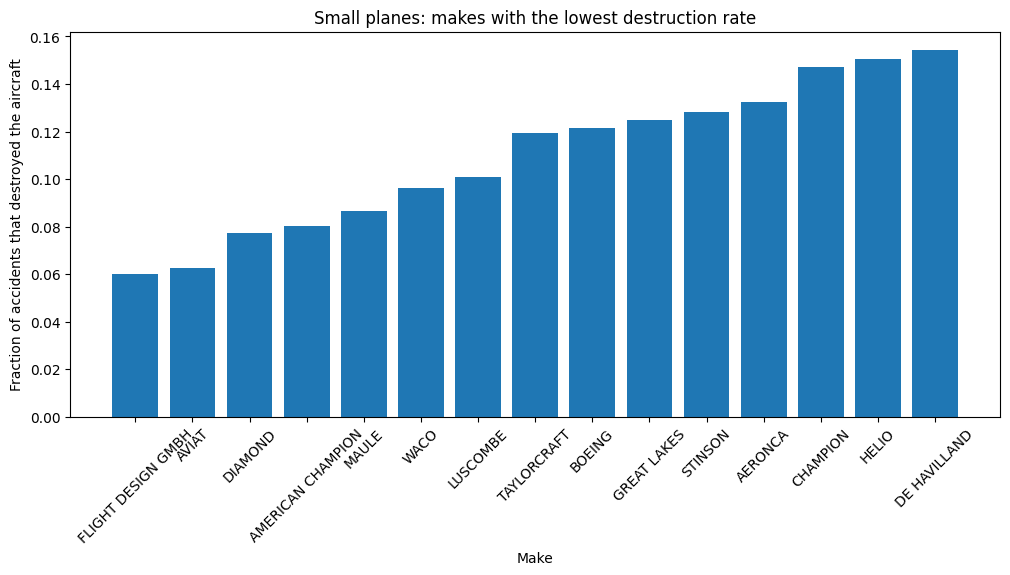

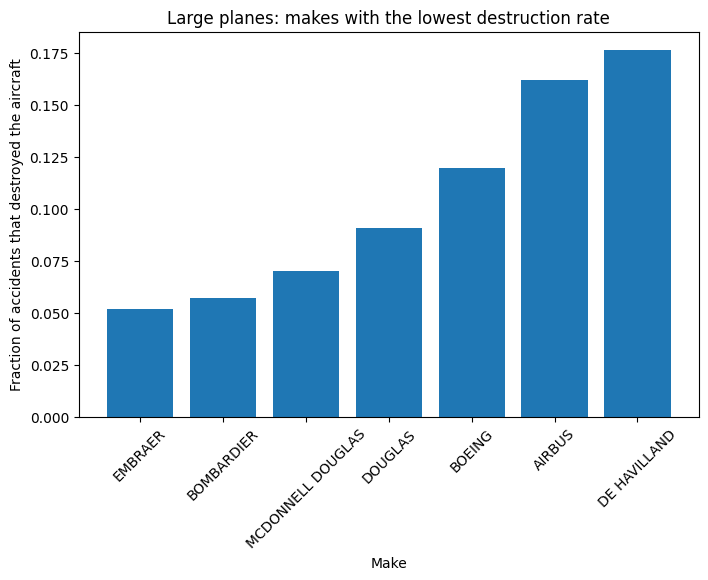

                    Fatal.Serious.Fraction  Destroyed    n
Make                                                      
FLIGHT DESIGN GMBH                0.370000   0.060000   50
AVIAT                             0.199552   0.062780  223
DIAMOND                           0.226885   0.077381  168
AMERICAN CHAMPION                 0.270115   0.080460   87
MAULE                             0.150313   0.086466  532
WACO                              0.123397   0.096154  104
LUSCOMBE                          0.229337   0.100817  367
TAYLORCRAFT                       0.305810   0.119266  327
BOEING                            0.171178   0.121547  362
GREAT LAKES                       0.151786   0.125000   56
STINSON                           0.200534   0.128079  406
AERONCA                           0.254331   0.132616  558
CHAMPION                          0.259804   0.147059  476
HELIO                             0.156600   0.150685   73
DE HAVILLAND                      0.248146   0.154270  3

In [7]:
best_small_destroyed = small_makes.sort_values("Destroyed").head(15)
best_large_destroyed = large_makes.sort_values("Destroyed").head(15)

plt.figure(figsize=(12, 5))
plt.bar(best_small_destroyed.index, best_small_destroyed["Destroyed"])
plt.title("Small planes: makes with the lowest destruction rate")
plt.xlabel("Make")
plt.ylabel("Fraction of accidents that destroyed the aircraft")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(best_large_destroyed.index, best_large_destroyed["Destroyed"])
plt.title("Large planes: makes with the lowest destruction rate")
plt.xlabel("Make")
plt.ylabel("Fraction of accidents that destroyed the aircraft")
plt.xticks(rotation=45)
plt.show()

print(best_small_destroyed)
print(best_large_destroyed)

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Discussion and recommendations:

For small aircraft, Maule and Waco show good results in both injury fraction and destruction rate. Maule is the strongest recommendation because it has a relatively low injury fraction (0.150) and destruction rate (0.086), based on 532 accidents. Waco also performs well, with an injury fraction of 0.123 and a destruction rate of 0.096. Aviat and Diamond have low destruction rates, but their injury fractions are slightly higher. Cessna has the largest number of accidents (24,939) and a relatively high injury fraction (0.241).

For large aircraft, McDonnell Douglas, Bombardier and Embraer have the lowest injury fractions and destruction rates. Boeing also shows good results and has the largest sample, with 635 accidents, making its statistics more reliable. Airbus has higher values for both measures. Douglas and De Havilland have fewer accidents, so their results should be interpreted with caution.

The plots show that most accidents have an injury fraction close to 0, while some have values close to 1. This means that many accidents result in no serious injuries, while a smaller number lead to severe consequences. The distributions also show that a few serious accidents can strongly influence the average values, especially for makes with fewer observations.

Based on these results, Maule and Waco are good options among small aircraft, followed by Aviat and Diamond. For large aircraft, McDonnell Douglas, Bombardier, Embraer and Boeing show better results.

However, these findings only describe the severity of recorded accidents. They do not measure the actual safety of each aircraft make, since the dataset does not include the number of flights or total flight hours.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

                          Fatal.Serious.Fraction  Destroyed    n
Make.Model                                                      
BOEING 757232                           0.000000   0.000000   10
MCDONNELL DOUGLAS MD11F                 0.000000   0.071429   14
BOEING 777                              0.000000   0.041667   24
BOEING 757222                           0.000000   0.000000   10
MCDONNELL DOUGLAS MD83                  0.000871   0.071429   14
MCDONNELL DOUGLAS MD88                  0.002123   0.000000   26
MCDONNELL DOUGLAS DC951                 0.005218   0.083333   12
MCDONNELL DOUGLAS MD80                  0.006722   0.000000   16
EMBRAER EMB145LR                        0.006944   0.000000   12
BOMBARDIER CL6002C10                    0.018402   0.000000   14
AIRBUS A320232                          0.025573   0.000000   10
BOEING 727200                           0.041993   0.040000   25
BOEING 747400                           0.052428   0.076923   13
MCDONNELL DOUGLAS DC1030 

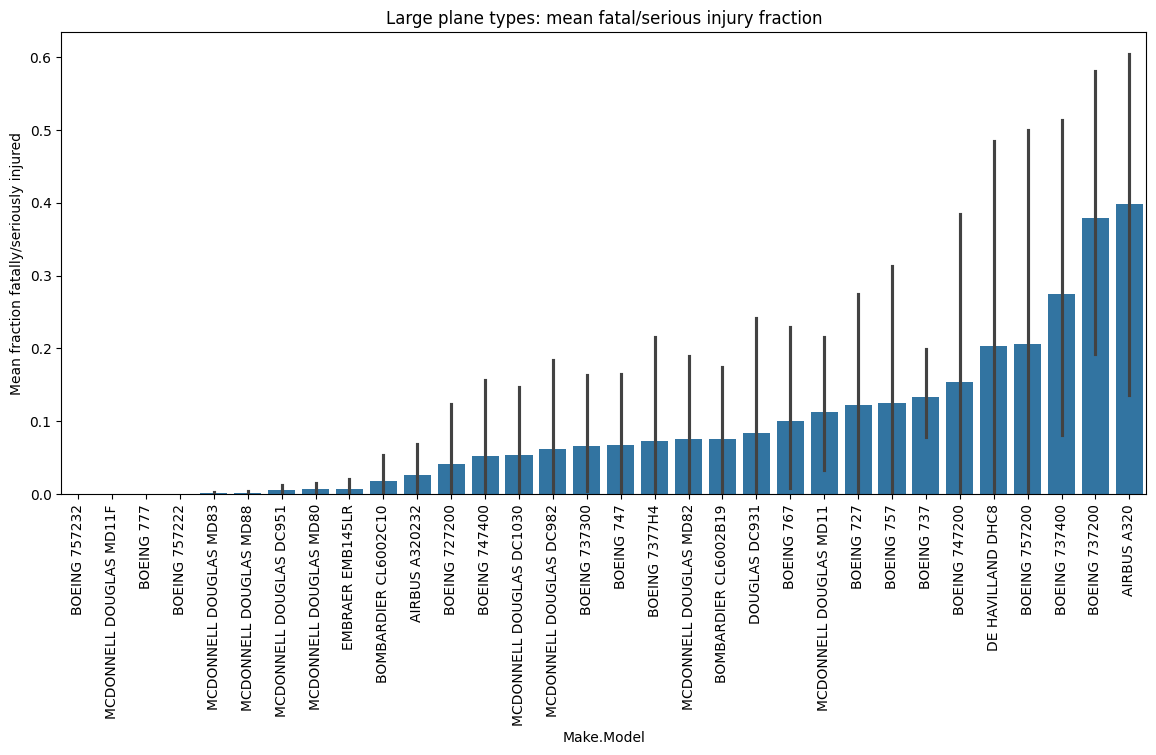

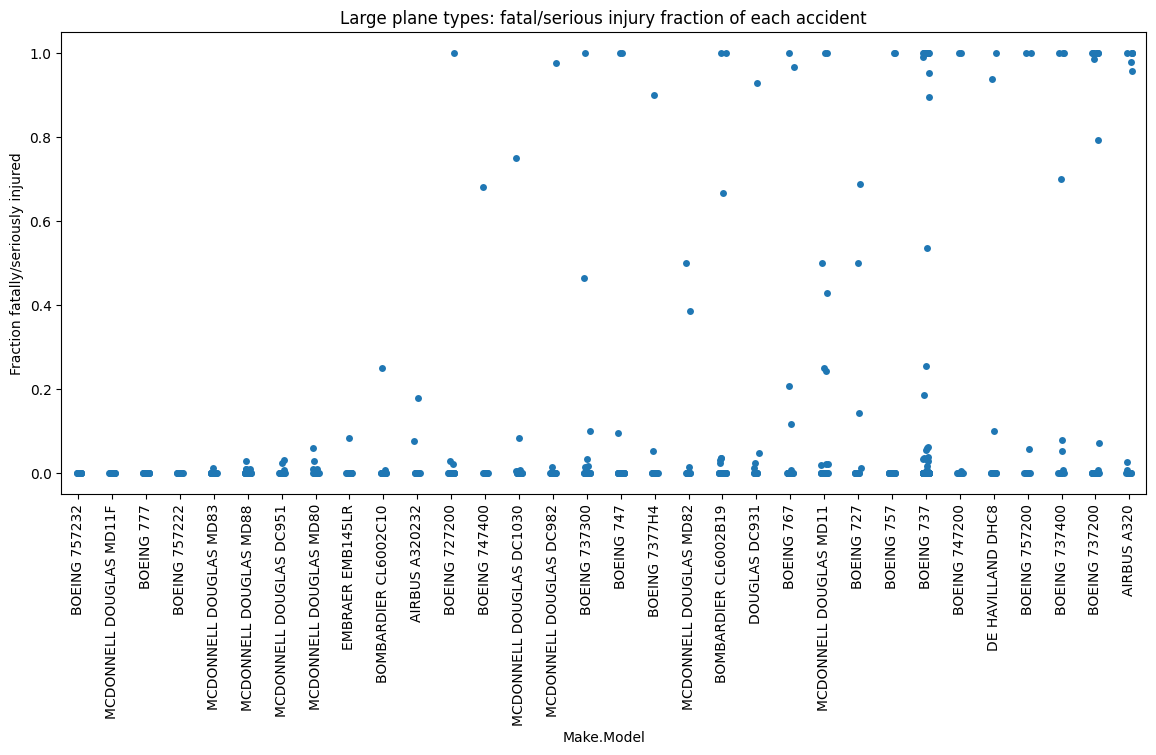

In [8]:
large_types = summary_table(large, "Make.Model", 10).sort_values("Fatal.Serious.Fraction")
print(large_types)

large_types_data = pd.concat([large[large["Make.Model"] == t] for t in large_types.index])

plt.figure(figsize=(14, 6))
sns.barplot(data=large_types_data, x="Make.Model", y="Fatal.Serious.Fraction")
plt.title("Large plane types: mean fatal/serious injury fraction")
plt.ylabel("Mean fraction fatally/seriously injured")
plt.xticks(rotation=90)
plt.show()

plt.figure(figsize=(14, 6))
sns.stripplot(data=large_types_data, x="Make.Model", y="Fatal.Serious.Fraction")
plt.title("Large plane types: fatal/serious injury fraction of each accident")
plt.ylabel("Fraction fatally/seriously injured")
plt.xticks(rotation=90)
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

                 Fatal.Serious.Fraction  Destroyed    n
Make.Model                                             
PIPER PA18160                  0.045455   0.030303   33
CESSNA 180A                    0.065574   0.032787   61
CESSNA 185E                    0.073611   0.055556   36
BOEING E75                     0.075758   0.121212   33
PIPER PA20                     0.079545   0.053030  132
BEECH 1900D                    0.085968   0.086957   46
CESSNA A185E                   0.086458   0.031250   64
CESSNA 185F                    0.090453   0.097087  103
MAULE M4220C                   0.095238   0.095238   42
SCHWEIZER G164A                0.100660   0.168317  101


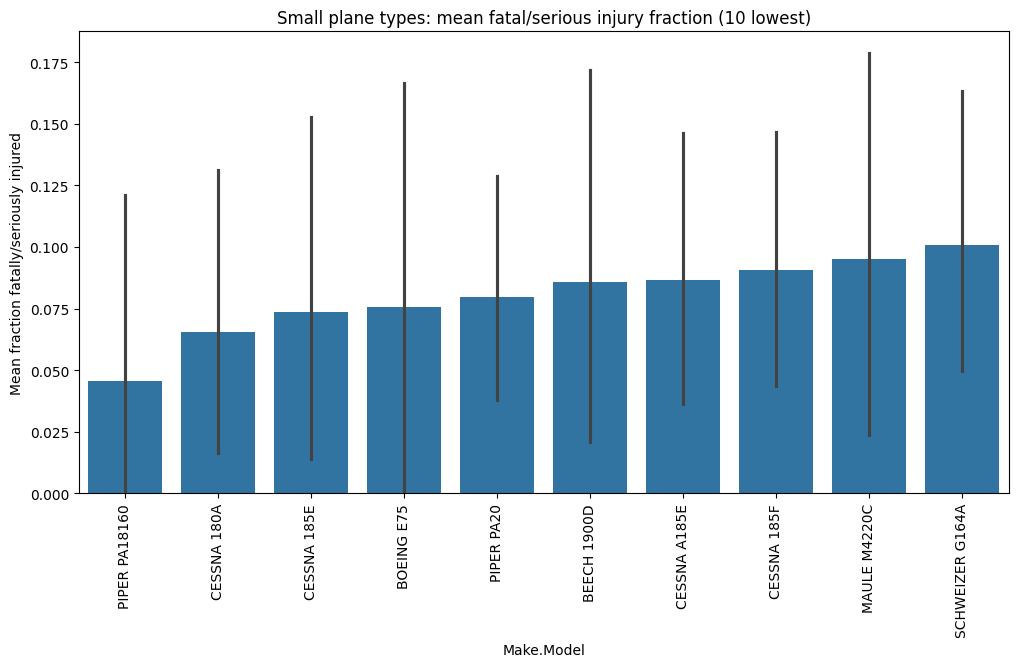

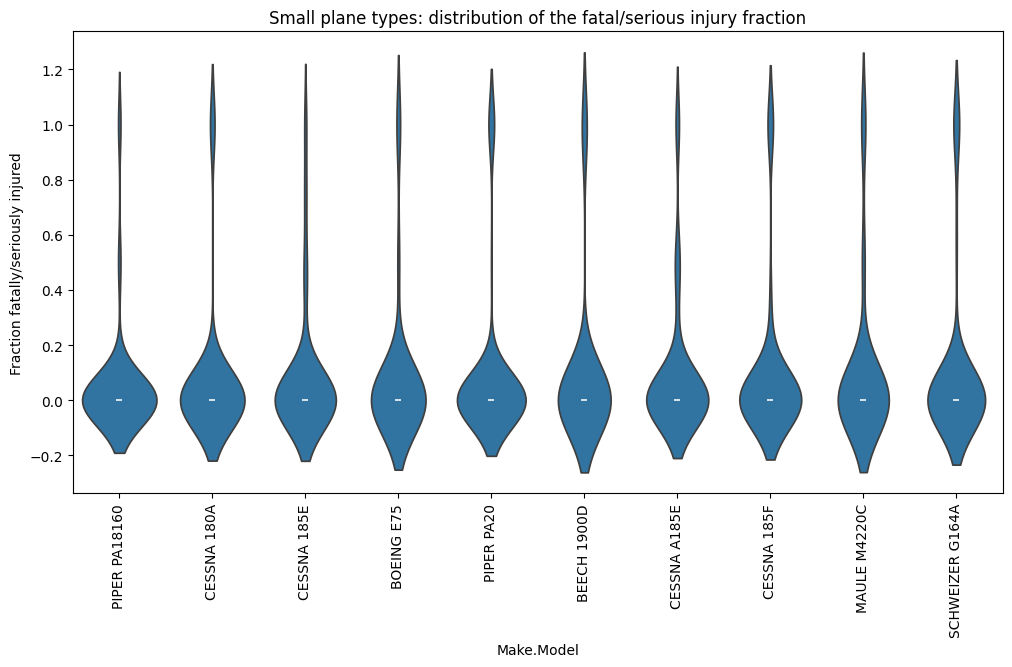

In [9]:
small_types = summary_table(small, "Make.Model", 30).sort_values("Fatal.Serious.Fraction")
best_small_types = small_types.head(10)
print(best_small_types)

best_small_types_data = pd.concat([small[small["Make.Model"] == t] for t in best_small_types.index])

plt.figure(figsize=(12, 6))
sns.barplot(data=best_small_types_data, x="Make.Model", y="Fatal.Serious.Fraction")
plt.title("Small plane types: mean fatal/serious injury fraction (10 lowest)")
plt.ylabel("Mean fraction fatally/seriously injured")
plt.xticks(rotation=90)
plt.show()

plt.figure(figsize=(12, 6))
sns.violinplot(data=best_small_types_data, x="Make.Model", y="Fatal.Serious.Fraction")
plt.title("Small plane types: distribution of the fatal/serious injury fraction")
plt.ylabel("Fraction fatally/seriously injured")
plt.xticks(rotation=90)
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Discussion of Specific Airplane Types

For larger aircraft, the Boeing 777, MD-88, MD-83 and MD-80 have very low average injury fractions. The Embraer EMB-145LR and Bombardier CL-600-2C10 also show good results. Among these aircraft, the Boeing 777, MD-88 and Boeing 727-200 have more accident records, making their results more reliable. The Boeing 737 has the largest sample, with 121 accidents, and shows average results. On the other hand, the Airbus A320, Boeing 737-200 and Boeing 737-400 have higher injury fractions. The Boeing 737-200 is particularly concerning because it has 26 recorded accidents.

For smaller aircraft, the Piper PA-18-160, Cessna 180A, Cessna 185E and Piper PA-20 have some of the lowest average injury fractions. The Cessna 185F and Piper PA-20 are particularly interesting because they have more accident records than most of the other types in this group. The Schweizer G164A also has a relatively low injury fraction, although its destruction rate is higher.

The plots show that most accidents have low injury fractions, while a smaller number have values close to 1. This suggests that many accidents do not result in serious injuries, but some have much more severe consequences. The confidence intervals also show that results based on fewer accidents are less reliable.

Based on these findings, the Boeing 777, MD-80 series, Embraer 145 and Bombardier CL-600-2C10 show promising results among larger aircraft. For smaller aircraft, the Piper PA-18 and PA-20, Cessna 180 and 185, and Maule M-4 are worth considering.

However, these results should be interpreted with caution. They describe the severity of recorded accidents and do not establish the actual probability of an accident occurring for each aircraft type.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

                         Fatal.Serious.Fraction  Destroyed      n
Size  Weather.Condition                                          
Large IMC                              0.223276   0.238095    126
      VMC                              0.035739   0.033275    571
Small IMC                              0.692076   0.600792   4291
      VMC                              0.222715   0.165292  49113


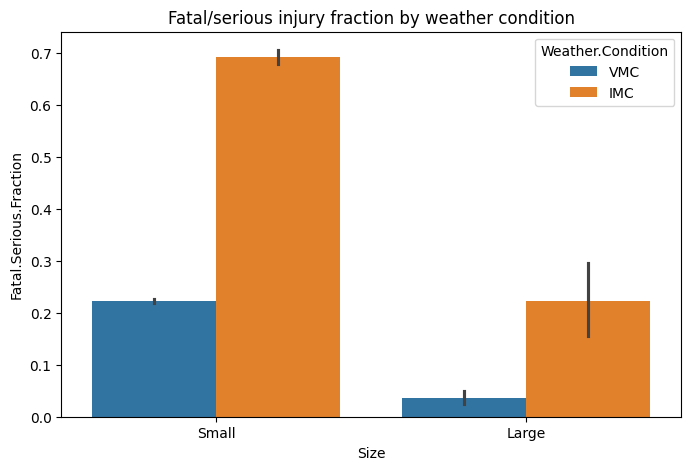

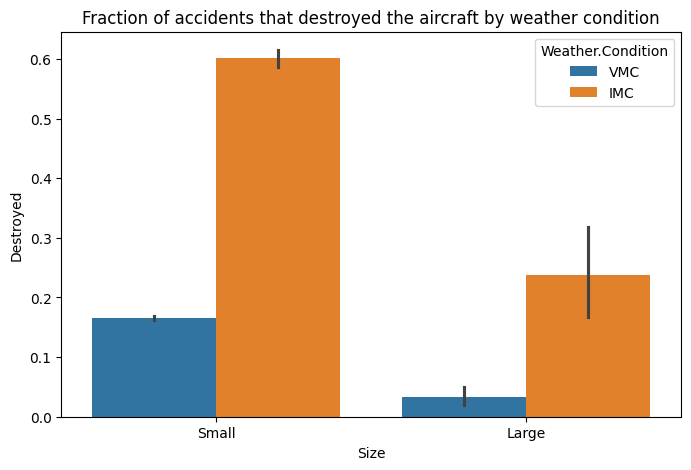

In [10]:
weather = df[(df["Weather.Condition"] == "VMC") | (df["Weather.Condition"] == "IMC")]

weather_table = weather.groupby(["Size", "Weather.Condition"])[["Fatal.Serious.Fraction", "Destroyed"]].mean()
weather_table["n"] = weather.groupby(["Size", "Weather.Condition"])["Destroyed"].count()
print(weather_table)

plt.figure(figsize=(8, 5))
sns.barplot(data=weather, x="Size", y="Fatal.Serious.Fraction", hue="Weather.Condition")
plt.title("Fatal/serious injury fraction by weather condition")
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=weather, x="Size", y="Destroyed", hue="Weather.Condition")
plt.title("Fraction of accidents that destroyed the aircraft by weather condition")
plt.show()

Factor 1: Weather Conditions (VMC vs. IMC)

The results show that accidents occurring in instrument meteorological conditions (IMC) are generally more severe than those in visual meteorological conditions (VMC). For small aircraft, the average injury fraction is 0.692 in IMC, compared to 0.223 in VMC. The destruction rate is also higher in IMC (0.601) than in VMC (0.165).

The same pattern appears among large aircraft. The injury fraction is 0.223 in IMC compared to 0.036 in VMC, while the destruction rate is 0.238 against 0.033. The confidence intervals also support this difference, as they do not overlap in either group.

These results suggest that poor visibility and difficult weather conditions are associated with more serious accident outcomes. However, they only describe the severity of accidents that occurred. They do not show whether flying in IMC increases the likelihood of an accident, since the dataset does not provide information on the total amount of flying under each weather condition.

                       Fatal.Serious.Fraction  Destroyed      n
Broad.phase.of.flight                                          
Maneuvering                          0.525467   0.466944   4326
Climb                                0.425590   0.428681   1304
Cruise                               0.351068   0.341493   6700
Approach                             0.349166   0.295712   4244
Descent                              0.344653   0.329372   1178
Go-around                            0.299770   0.286607   1120
Takeoff                              0.225098   0.215394   8315
Standing                             0.088878   0.126667    450
Landing                              0.034457   0.041685  11251
Taxi                                 0.015358   0.019345   1344


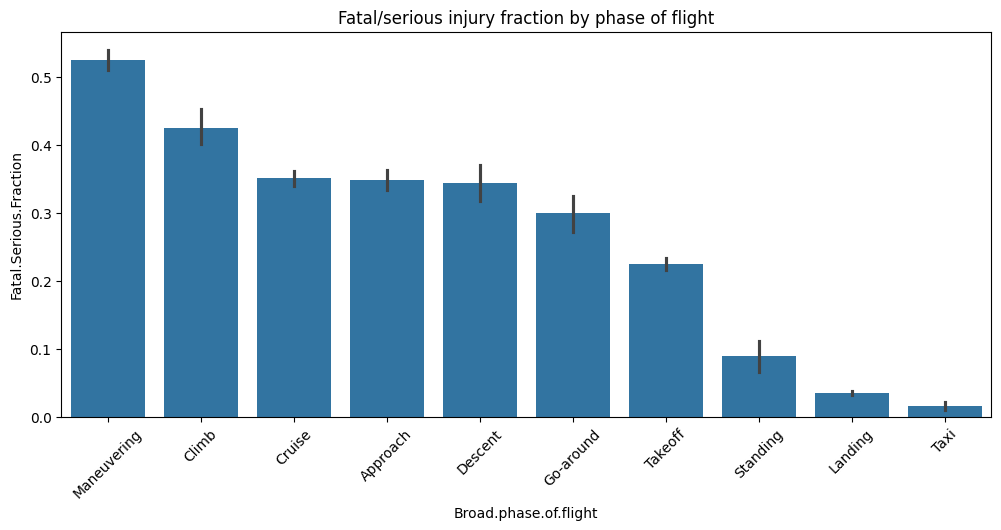

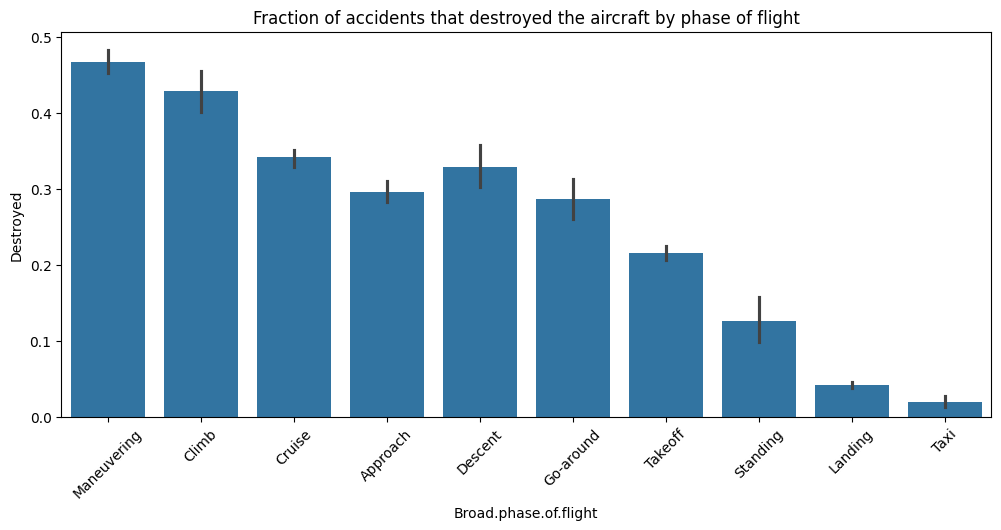

In [11]:
# Factor 2
phase_table = df.groupby("Broad.phase.of.flight")[["Fatal.Serious.Fraction", "Destroyed"]].mean()
phase_table["n"] = df["Broad.phase.of.flight"].value_counts()

phase_table = phase_table[phase_table["n"] >= 100].sort_values("Fatal.Serious.Fraction", ascending=False)
print(phase_table)

phase_data = pd.concat([df[df["Broad.phase.of.flight"] == phase] for phase in phase_table.index])

plt.figure(figsize=(12, 5))
sns.barplot(data=phase_data, x="Broad.phase.of.flight", y="Fatal.Serious.Fraction")
plt.title("Fatal/serious injury fraction by phase of flight")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 5))
sns.barplot(data=phase_data, x="Broad.phase.of.flight", y="Destroyed")
plt.title("Fraction of accidents that destroyed the aircraft by phase of flight")
plt.xticks(rotation=45)
plt.show()


Factor 2: Phase of Flight

The results show that the severity of accidents varies depending on the phase of flight. Maneuvering has the highest injury fraction (0.525) and destruction rate (0.467), followed by climb, cruise, approach and descent. These phases are therefore associated with more serious accident outcomes.

Landing accounts for the highest number of accidents (11,251), but the injury fraction (0.034) and destruction rate (0.042) are relatively low. Taxi accidents are even less severe, with an injury fraction of 0.015 and a destruction rate of 0.019. Take-off falls between these two groups and the more severe phases.

These findings suggest that accidents during maneuvering, climbing and cruising tend to have more serious consequences, while landing and taxi accidents are generally less severe. The intended use of an aircraft should therefore be considered, especially when its operations involve frequent low-level maneuvering.